# ATR: Average True Range

## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import datetime

import yfinance as yf

C:\Users\shash\AppData\Local\Temp\ipykernel_10288\1167104954.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, group_by="ticker")
[*********************100%***********************]  1 of 1 completed


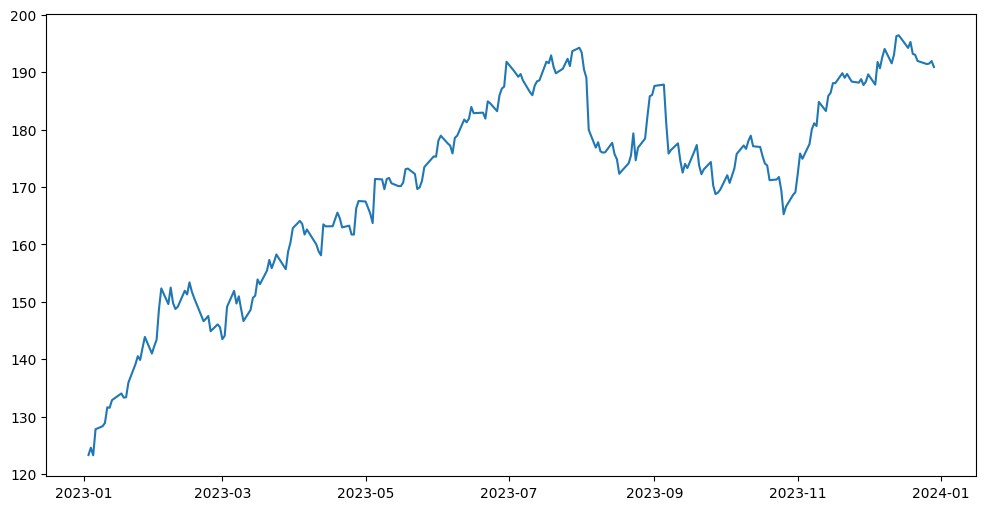

In [9]:
def download_data(ticker, start, end):
    data = yf.download(ticker, start=start, end=end, group_by="ticker")
    data = data[ticker]
    return pd.DataFrame(data)


start_date = datetime.datetime(2023, 1, 1)
end_date = datetime.datetime(2024, 1, 1)
stock_data = download_data('AAPL', start_date, end_date)
plt.figure(figsize=(12, 6))
plt.plot(stock_data['Close'])
plt.show()


In [11]:
def calculate_atr(data, period=14):
    data['H-L'] = data['High'] - data['Low']
    data['H-PC'] = abs(data['High'] - data['Close'].shift(1))
    data['L-PC'] = abs(data['Low'] - data['Close'].shift(1))
    data['TR'] = data[['H-L', 'H-PC', 'L-PC']].max(axis=1)
    data['ATR'] = data['TR'].rolling(window=period).mean()
    return data

df = calculate_atr(stock_data, period=14)
df

Price,Open,High,Low,Close,Volume,H-L,H-PC,L-PC,TR,ATR
Date,,,,,,,,,,
2023-01-03,128.468194,129.079567,122.443165,123.330650,112117500,6.636402,NaN,NaN,6.636402,NaN
2023-01-04,125.125343,126.870731,123.340517,124.602715,89113600,3.530215,3.540081,0.009866,3.540081,NaN
2023-01-05,125.361998,125.993097,123.024963,123.281342,80962700,2.968134,1.390383,1.577752,2.968134,NaN
2023-01-06,124.257557,128.478025,123.153130,127.817345,87754700,5.324895,5.196683,0.128212,5.324895,NaN
2023-01-09,128.655538,131.554653,128.083602,128.339981,70790800,3.471051,3.737309,0.266258,3.737309,NaN
...,...,...,...,...,...,...,...,...,...,...
2023-12-22,193.541439,193.769519,191.350000,191.974716,37149600,2.419518,0.723910,1.695608,2.419518,2.916022
2023-12-26,191.984587,192.262235,191.211137,191.429291,28919300,1.051099,0.287519,0.763580,1.051099,2.639081
2023-12-27,190.873995,191.875510,189.485739,191.528442,48087700,2.389771,0.446219,1.943552,2.389771,2.622083


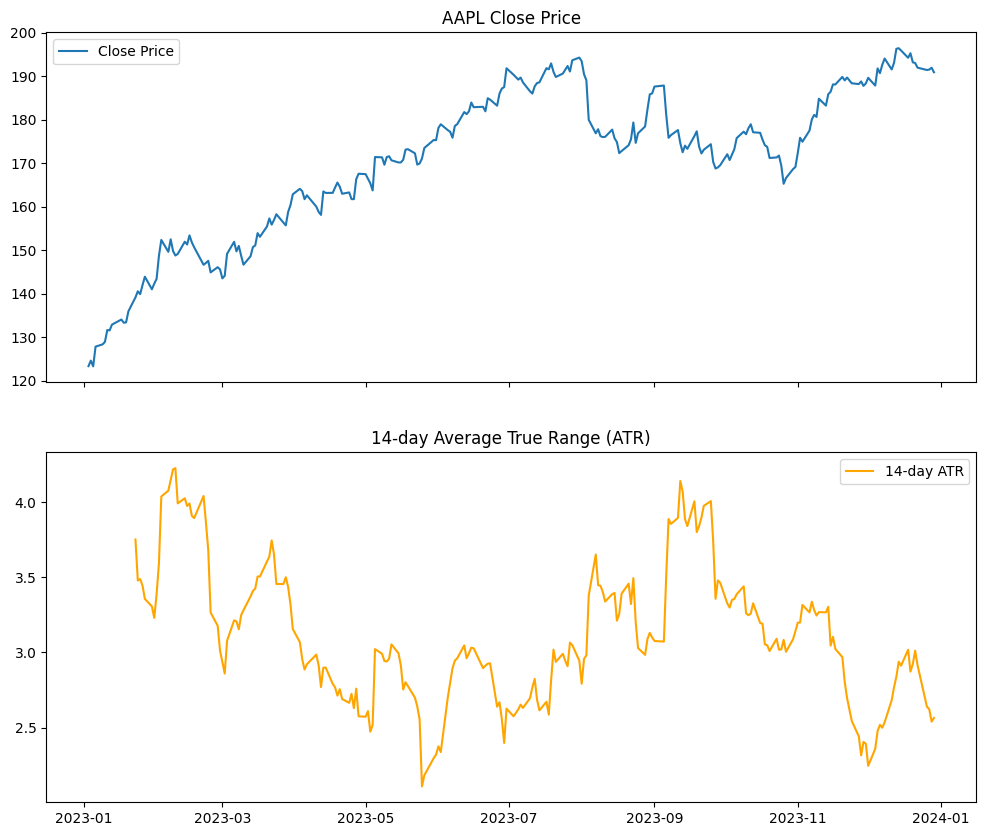

In [13]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)
ax1.plot(df['Close'], label='Close Price')
ax1.set_title('AAPL Close Price')
ax1.legend()
ax2.plot(df['ATR'], label='14-day ATR', color='orange')
ax2.set_title('14-day Average True Range (ATR)')
ax2.legend()
plt.show()